# AI productivity at work: what the measured studies show

**When a business gives work to AI, how much faster or better does that work get, and who gains most?**

This notebook rebuilds the processed tables from the raw readings (one row per figure per document), checks the headline figures against the build script output, and draws the charts.

In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / 'scripts'))
import build_data
raw = pd.read_csv(ROOT / 'data/raw/effect_readings.csv', dtype={'value_printed': str})
studies = pd.read_csv(ROOT / 'data/raw/studies.csv')
print('readings:', len(raw), '| documents:', raw.source_id.nunique(), '| studies:', studies.study_id.nunique())
print('missing values in key columns:', int(raw[['study_id','measure','group','value_printed','source_id']].isna().sum().sum()))
print('duplicate readings:', int(raw.duplicated(['study_id','version','measure','group','source_id']).sum()))
studies[['study_id','published','design','scope']]

readings: 75 | documents: 21 | studies: 7
missing values in key columns: 0
duplicate readings: 0


,study_id,published,design,scope
0,support,"Quarterly Journal of Economics 140(2), 2025 (NBER WP 31161, 2023)",staggered roll-out at one firm,single task
1,writing,"Science, 2023",randomised experiment,single task
2,coding_test,"arXiv, 2023",randomised experiment,single task
3,consulting,"Organization Science, 2025 (HBS working paper, 2023)",randomised experiment,single task
4,developers_field,"Management Science, 2025",three randomised field experiments,day-to-day coding work
5,us_survey,"Federal Reserve Bank of St. Louis, 2025",national survey,whole job
6,denmark,"Becker Friedman Institute working paper, 2025",surveys linked to administrative records,whole job


## 1. Rebuild and check agreement between documents

A figure printed to d decimals stands for anything within half a unit of its last digit. The build stops if two documents disagree, and tests two identities: the coding test's time cut from its two group means, and the St. Louis Fed's 5.4% of hours as about 2.2 hours of a 40-hour week.

In [2]:
tidy, head, exp, figures = build_data.build()
print(tidy.verification.value_counts().to_string())
print()
print('set aside:', raw[raw.note.fillna('').str.startswith('set_aside')][['study_id','measure','value_printed','source_id','note']].to_string(index=False))

verification
two-or-more-documents    25
one-document              9

set aside:   study_id            measure value_printed source_id                                            note
consulting quality_change_pct            40        B5 set_aside: printed as 'over 40%', a lower bound


## 2. Recompute the headline figures independently

In [3]:
def pick(study, measure, group, version=None):
    t = raw[(raw.study_id==study)&(raw.measure==measure)&(raw.group==group)&~raw.note.fillna('').str.startswith('set_aside')]
    if version: t = t[t.version==version]
    return float(max(t.value_printed, key=lambda v: len(v.split('.')[-1]) if '.' in v else 0))

task = [-pick('coding_test','time_change_pct','all'), -pick('writing','time_change_pct','all'),
        pick('developers_field','tasks_completed_change_pct','all'), pick('consulting','speed_gain_pct','all'),
        pick('support','resolutions_per_hour_change_pct','all','QJE 2025')]
job = [pick('us_survey','time_saved_share_of_hours_pct','ai_users'), pick('denmark','time_saved_share_of_hours_pct','ai_users')]
mine = {'task_gain_min_pct': min(task), 'task_gain_max_pct': max(task),
        'whole_job_saving_min_pct': min(job), 'whole_job_saving_max_pct': max(job),
        'support_gain_least_experienced_pct': pick('support','resolutions_per_hour_change_pct','least_experienced','QJE 2025'),
        'consulting_least_pct': pick('consulting','performance_change_pct','least_experienced'),
        'consulting_most_pct': pick('consulting','performance_change_pct','most_experienced'),
        'consulting_outside_frontier_pts': pick('consulting','correct_answer_change_pts','outside_frontier')}
w, wo = pick('coding_test','minutes_to_complete','with_ai'), pick('coding_test','minutes_to_complete','without_ai')
mine['coding_time_cut_pct_recomputed'] = round(100*(wo-w)/wo, 2)
saved = pd.read_csv(ROOT / 'data/processed/headline_figures.csv', index_col=0)['value']
for k, x in mine.items():
    assert abs(float(saved[k]) - x) < 1e-9, (k, saved[k], x)
print('all', len(mine), 'recomputed figures match data/processed/headline_figures.csv')
pd.Series(mine)

all 9 recomputed figures match data/processed/headline_figures.csv


task_gain_min_pct                     15.00
task_gain_max_pct                     55.80
whole_job_saving_min_pct               2.80
whole_job_saving_max_pct               5.40
support_gain_least_experienced_pct    30.00
consulting_least_pct                  43.00
consulting_most_pct                   17.00
consulting_outside_frontier_pts      -19.00
coding_time_cut_pct_recomputed        55.76
dtype: float64

## 3. Headline effect per study

Each study uses its own measure (time per task, tasks per week, chats per hour, share of hours saved). They are shown side by side, not averaged.

In [4]:
head[['study_id','scope','gain_pct','effect_label','sample_size','verification']]

,study_id,scope,gain_pct,effect_label,sample_size,verification
0,coding_test,single task,55.80,less time on one coding task,95.0,two-or-more-documents
1,writing,single task,40.00,less time per writing task,453.0,two-or-more-documents
2,developers_field,day-to-day coding work,26.08,more tasks completed per week,4867.0,two-or-more-documents
3,consulting,single task,25.10,faster on consulting tasks,758.0,two-or-more-documents
4,support,single task,15.00,more chats resolved per hour,5172.0,two-or-more-documents
5,us_survey,whole job,5.40,"of work hours saved, US workers using AI",NaN,two-or-more-documents
6,denmark,whole job,2.80,"of work hours saved, Danish workers using AI",25000.0,two-or-more-documents


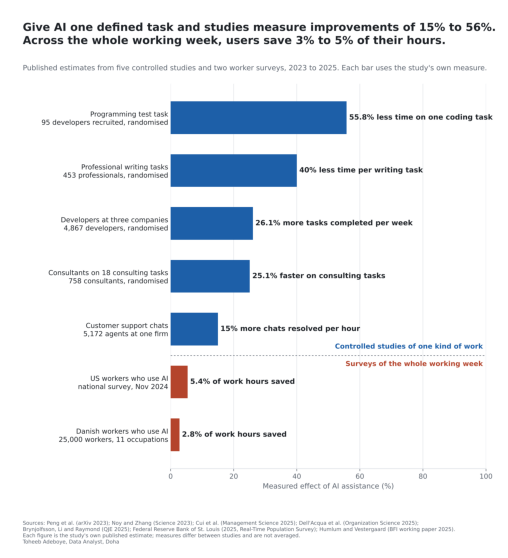

In [5]:
import make_charts
make_charts.headline(ROOT / 'images/ai-productivity-at-work.png')
from PIL import Image
img = Image.open(ROOT / 'images/ai-productivity-at-work.png')
fig, ax = plt.subplots(figsize=(8, 8.8)); ax.imshow(img); ax.axis('off'); plt.show()

## 4. Who gains most

        study_id                                study  least_low  least_high  most_low  most_high                                                                                      note
      consulting     Consultants (graded performance)       43.0        43.0      17.0       17.0                                                           below-average vs top performers
developers_field Software developers (tasks per week)       27.0        39.0       8.0       13.0                  recent hires and juniors vs seniors; ranges across the three experiments
         support    Customer support (chats per hour)       30.0        30.0       NaN        NaN most experienced: 'small gains in speed and small declines in quality', no figure printed


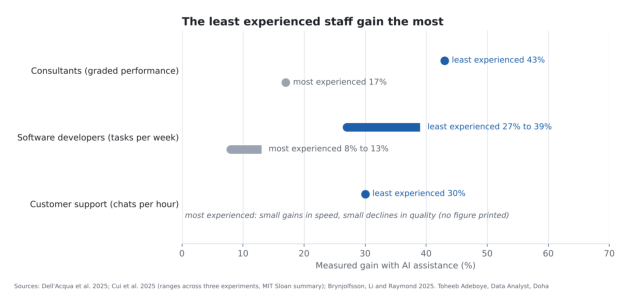

In [6]:
print(exp.to_string(index=False))
make_charts.by_experience(ROOT / 'images/gain-by-experience.png')
img = Image.open(ROOT / 'images/gain-by-experience.png')
fig, ax = plt.subplots(figsize=(10, 4.6)); ax.imshow(img); ax.axis('off'); plt.show()

## 5. Findings

1. In five controlled studies of one kind of work, AI assistance improved the measured outcome by 15% (customer support chats per hour) to 55.8% (less time on one coding task).
2. In two surveys covering the whole working week, workers who use AI report saving 5.4% (US) and 2.8% (Denmark) of their hours.
3. The least experienced staff gained most: 30% in customer support, 43% for below-average consultants against 17% for top performers, 27% to 39% for junior developers against 8% to 13% for seniors.
4. On a task outside what the AI did well, consultants using it were 19 percentage points less likely to reach the correct answer (one document).